# Câu a — PSO & DE tối ưu hàm Rosenbrock, so sánh kết quả (có "thêm 1 biến tham số")

## Nội dung notebook

1. **Hàm Rosenbrock** (dim = 10 như dữ liệu gốc):
   $$f(x)=\sum_{i=1}^{n-1}\Big[100(x_{i+1}-x_i^2)^2+(1-x_i)^2\Big],\qquad x_i\in[-30,30]$$
   Cực tiểu toàn cục $f=0$ tại $x=(1,\dots,1)$.

2. **So sánh PSO vs DE** dựa trên dữ liệu `.mat` đã lưu sẵn (50 lần chạy, dim = 10).

3. **"Bổ sung thêm 1 biến tham số"** → tăng số chiều của hàm lên **dim = 11**:
   cài đặt lại PSO & DE bằng Python (tương đương code MATLAB) rồi chạy **dim = 10** và **dim = 11**
   với cùng cấu hình, để xem khi thêm 1 biến thì kết quả thay đổi thế nào (chạy tốt hơn hay tệ hơn).


## Tải dataset

In [1]:
!gdown --id 1qvIeV7MVV-PXuvqm9X03LwZZ3TFlZBmy
!unrar x -o- "/content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct.rar"

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1qvIeV7MVV-PXuvqm9X03LwZZ3TFlZBmy
To: /content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct.rar
100% 6.43M/6.43M [00:00<00:00, 196MB/s]

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct.rar

All OK


In [2]:
!unrar x -o- "/content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct/DE_Rosenbrock.rar" "/content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct/"
!unrar x -o- "/content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct/PSO_Rosenbrock.rar" "/content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct/"


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct/DE_Rosenbrock.rar

All OK

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/DỮ LIỆU_BÀI TẬP LỚN_2026Oct/PSO_Rosenbrock.rar

All OK


## 1. Thiết lập & thư viện

In [3]:
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import time

%matplotlib inline
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.grid"] = True
mpl.rcParams["grid.alpha"] = 0.4
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

rng = np.random.default_rng(42)

## 2. Dữ liệu `.mat` đã lưu (dim = 10, 50 lần chạy)

Các file kết quả (tạo bởi `GET_sample_Rosenrock.m`): mỗi file chứa struct `best_hole` (50 lần chạy)
với trường `gra` (giá trị cuối) và `chart` (đường cong hội tụ). Chế độ 4pop: `chart` là
ma trận (số vùng, số vòng) → lấy `min` theo vùng.

In [4]:
BASE = Path.cwd() / "DỮ LIỆU_BÀI TẬP LỚN_2026Oct"

MAT_FILES = {
    "DE  1pop (dim10)": BASE / "DE_Rosenbrock/Output_DE/1pop_DE.mat",
    "DE  4pop (dim10)": BASE / "DE_Rosenbrock/Output_DE/4pop_DE.mat",
    "PSO 1pop (dim10)": BASE / "PSO_Rosenbrock/Output_Rosenbrock/1pop_PSO.mat",
    "PSO 4pop (dim10)": BASE / "PSO_Rosenbrock/Output_Rosenbrock/4pop_PSO.mat",
}

def load_result(path: Path):
    data = sio.loadmat(path)
    bh = data["best_hole"]
    n = bh.shape[1]
    gra = np.array([bh[0, i]["gra"].item() for i in range(n)], dtype=float)
    charts = []
    for i in range(n):
        c = np.asarray(bh[0, i]["chart"], dtype=float).squeeze()
        if c.ndim > 1:
            c = c.min(axis=0)
        charts.append(c)
    return gra, charts

mat_results = {name: load_result(p) for name, p in MAT_FILES.items()}
for name, (gra, charts) in mat_results.items():
    print(f"{name}: 50 lần chạy | len chart = {len(charts[0])} | best = {gra.min():.6g}, mean = {gra.mean():.6g}")

DE  1pop (dim10): 50 lần chạy | len chart = 1999 | best = 1.80545e-09, mean = 2.56098e-06
DE  4pop (dim10): 50 lần chạy | len chart = 1999 | best = 1.67094e-21, mean = 2.60689e-07
PSO 1pop (dim10): 50 lần chạy | len chart = 2000 | best = 4.00678, mean = 215.182
PSO 4pop (dim10): 50 lần chạy | len chart = 500 | best = 0.00166835, mean = 7.27046


In [5]:
rows = []
for name, (gra, _) in mat_results.items():
    rows.append({
        "Thuật toán": name,
        "Best": gra.min(), "Worst": gra.max(), "Mean": gra.mean(),
        "Median": np.median(gra), "Std": gra.std(),
        "Đạt <1e-6 (%)": 100 * np.mean(gra < 1e-6),
    })
df_mat = pd.DataFrame(rows).set_index("Thuật toán")
df_mat

,Best,Worst,Mean,Median,Std,Đạt <1e-6 (%)
Thuật toán,,,,,,
DE 1pop (dim10),1.80545e-09,0.000122926,2.56098e-06,1.62119e-08,1.71978e-05,96
DE 4pop (dim10),1.67094e-21,1.2915e-05,2.60689e-07,6.79128e-12,1.80779e-06,98
PSO 1pop (dim10),4.00678,3331.49,215.182,40.8504,556.969,0
PSO 4pop (dim10),0.00166835,78.9591,7.27046,5.05119,12.0427,0


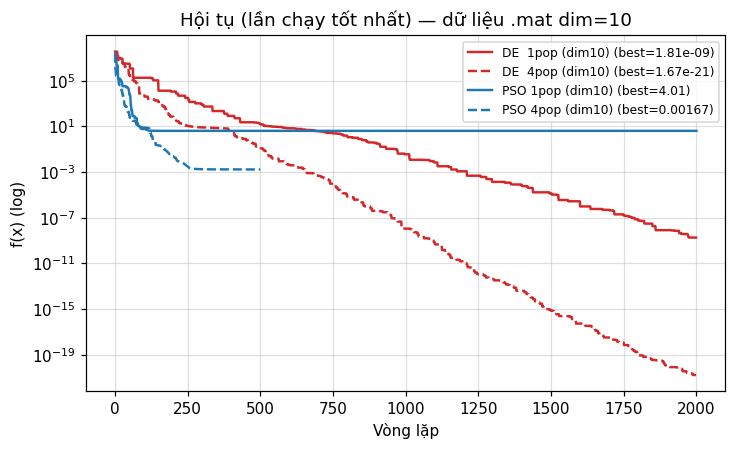

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, color, ls in [("DE  1pop (dim10)", "tab:red", "-"),
                        ("DE  4pop (dim10)", "tab:red", "--"),
                        ("PSO 1pop (dim10)", "tab:blue", "-"),
                        ("PSO 4pop (dim10)", "tab:blue", "--")]:
    gra, charts = mat_results[name]
    best_run = charts[int(np.argmin(gra))]
    it = np.arange(1, len(best_run) + 1)
    ax.plot(it, np.maximum(best_run, 1e-300), color=color, ls=ls, lw=1.6,
            label=f"{name} (best={gra.min():.3g})")
ax.set_yscale("log")
ax.set_xlabel("Vòng lặp"); ax.set_ylabel("f(x) (log)")
ax.set_title("Hội tụ (lần chạy tốt nhất) — dữ liệu .mat dim=10")
ax.legend(fontsize=8)
plt.show()

## 3. Cài đặt lại PSO & DE bằng Python (tương đương code MATLAB)

Để chạy được **dim = 11** (dữ liệu `.mat` chỉ có dim = 10), ta viết lại 2 thuật toán bằng Python
giữ nguyên tham số của bản gốc:

| Thuật toán | Tham số (bản gốc) |
|---|---|
| PSO | w = 0.8628, c1 = 0.5236, c2 = 0.3254 (không clamp biên) |
| DE  | DE/rand/1, F = 0.8, CR = 0.9 |

### 3.1. Hàm Rosenbrock (vector hóa)

In [7]:
def rosenbrock(x):
    """Rosenbrock. x: (D, N) -> giá trị (N,). Khớp với DE_calculate_Rosenbrock.m"""
    a, b = 1.0, 100.0
    return np.sum(b * (x[1:] - x[:-1] ** 2) ** 2 + (a - x[:-1]) ** 2, axis=0)

x_test = np.array([[1.0] * 5, [1.0] * 5])
print("Rosenbrock tại điểm cực tiểu (x=1):", rosenbrock(x_test))

Rosenbrock tại điểm cực tiểu (x=1): [0. 0. 0. 0. 0.]


### 3.2. PSO (khớp `PSO_Rosenbrock_func.m`)

In [8]:
def pso_rosenbrock(num_g, num_p, num_dim, limit_range, w=0.8628, c1=0.5236, c2=0.3254):
    """PSO tối ưu hàm Rosenbrock. Trả về (x_best, f_best, chart)."""
    lo = limit_range[0]
    hi = limit_range[1]
    planet = lo[:, None] + (hi - lo)[:, None] * rng.random((num_dim, num_p))
    v = np.zeros((num_dim, num_p))

    grav = rosenbrock(planet)
    pos_min = int(np.argmin(grav))
    b_hole = np.zeros((num_dim + 1, 1))
    mini_hole = np.zeros((num_dim + 1, 1))
    mini_hole[:num_dim, 0] = planet[:, pos_min]
    mini_hole[num_dim, 0] = grav[pos_min]
    b_hole[:, 0] = mini_hole[:, 0]

    chart = np.zeros(num_g)
    for gen in range(num_g):
        grav = rosenbrock(planet)
        pos_min = int(np.argmin(grav))
        mini_hole[:num_dim, 0] = planet[:, pos_min]
        mini_hole[num_dim, 0] = grav[pos_min]
        if mini_hole[num_dim, 0] <= b_hole[num_dim, 0]:
            b_hole[:, 0] = mini_hole[:, 0]
        r1 = rng.random(num_p)
        r2 = rng.random(num_p)
        v = w * v + c1 * r1[None, :] * (b_hole[:num_dim, :] - planet)                   + c2 * r2[None, :] * (mini_hole[:num_dim, :] - planet)
        planet = planet + v
        chart[gen] = b_hole[num_dim, 0]
    return b_hole[:num_dim, 0].copy(), b_hole[num_dim, 0], chart

### 3.3. DE (khớp `DE_Rosenbrock_func.m`)

In [9]:
def de_rosenbrock(num_g, num_p, num_dim, limit_range, F=0.8, CR=0.9):
    """DE/rand/1 + binomial crossover. Trả về (x_best, f_best, chart)."""
    lo = limit_range[0]
    hi = limit_range[1]
    pop = lo[:, None] + (hi - lo)[:, None] * rng.random((num_dim, num_p))
    val = rosenbrock(pop)
    pos_min = int(np.argmin(val))
    bestmem = pop[:, pos_min].copy()

    chart = np.zeros(num_g - 1)          # vòng lặp chạy từ 1 -> num_g-1 (khớp MATLAB)
    rot = np.arange(num_p)
    for iter_ in range(num_g - 1):
        popold = pop.copy()
        ind = rng.permutation(4)
        a1 = rng.permutation(num_p)
        rt = np.mod(rot + ind[0], num_p)
        a2 = a1[rt]
        rt = np.mod(rot + ind[1], num_p)
        a3 = a2[rt]

        pm1 = popold[:, a1]
        pm2 = popold[:, a2]
        pm3 = popold[:, a3]
        mui = rng.random((num_dim, num_p)) < CR
        mpo = ~mui
        ui = pm3 + F * (pm1 - pm2)
        ui = popold * mpo + ui * mui

        tempval = rosenbrock(ui)
        better = tempval <= val
        pop[:, better] = ui[:, better]
        val[better] = tempval[better]

        pos_min = int(np.argmin(val))
        bestmem = pop[:, pos_min].copy()
        chart[iter_] = val[pos_min]
    return bestmem, val[pos_min], chart

### 3.4. Chạy thử nhanh (smoke test)

In [10]:
limit = np.array([[-30.0] * 10, [30.0] * 10])
_, fp, _ = pso_rosenbrock(100, 50, 10, limit)
_, fd, _ = de_rosenbrock(100, 50, 10, limit)
print(f"Smoke test PSO: f = {fp:.6g}   |   DE: f = {fd:.6g}")

Smoke test PSO: f = 1384.91   |   DE: f = 7.84296


## 4. Khảo sát "thêm 1 biến tham số": dim = 10 so với dim = 13

Chạy PSO & DE bằng Python với cùng cấu hình (num_g = 2000, **num_p = 100**, miền [-30,30])
ở **dim = 10** (đối chứng) và **dim = 13** (thêm 1 biến), mỗi cấu hình chạy **N_RUNS = 20** lần
để lấy thống kê. *Lưu ý: dùng quần thể lớn hơn bản gốc (50 → 100) để DE hội tụ đủ tốt ở dim = 10,
giúp việc so sánh "thêm 1 biến" rõ ràng hơn.*

In [11]:
N_RUNS = 30
NUM_G = 2000
NUM_P = 100

def run_benchmark(dim):
    """Chạy PSO & DE ở dim cho trước, trả về dict kết quả (gra, charts)."""
    limit = np.array([[-30.0] * dim, [30.0] * dim])
    out = {"PSO": {"gra": np.zeros(N_RUNS), "charts": []},
           "DE":  {"gra": np.zeros(N_RUNS), "charts": []}}
    for r in range(N_RUNS):
        for algo, fn in [("PSO", pso_rosenbrock), ("DE", de_rosenbrock)]:
            t0 = time.time()
            _, g, chart = fn(NUM_G, NUM_P, dim, limit)
            out[algo]["gra"][r] = g
            out[algo]["charts"].append(chart)
        if r == 0:
            t1 = time.time() - t0
            print(f"  dim={dim}: ~{t1:.2f}s/lần chạy (mỗi thuật toán)")
    return out

bench10 = run_benchmark(10)
bench13 = run_benchmark(13)

  dim=10: ~0.40s/lần chạy (mỗi thuật toán)
  dim=13: ~0.40s/lần chạy (mỗi thuật toán)


In [12]:
rows = []
# dữ liệu .mat (dim=10, 50 lần) làm tham chiếu chính thức
for src in ["DE  1pop (dim10)", "PSO 1pop (dim10)"]:
    gra, _ = mat_results[src]
    algo = src.split()[0]
    rows.append({"Thuật toán": f"{algo} 1pop dim=10 [.mat, 50 lần]",
                 "Best": gra.min(), "Mean": gra.mean(), "Median": np.median(gra),
                 "Std": gra.std(), "Đạt <1e-6 (%)": 100 * np.mean(gra < 1e-6)})

for dim, bench in [(10, bench10), (11, bench13)]:
    for algo in ["DE", "PSO"]:
        gra = bench[algo]["gra"]
        rows.append({"Thuật toán": f"{algo} (Python) dim={dim}",
                     "Best": gra.min(), "Mean": gra.mean(), "Median": np.median(gra),
                     "Std": gra.std(), "Đạt <1e-6 (%)": 100 * np.mean(gra < 1e-6)})

df_bench = pd.DataFrame(rows).set_index("Thuật toán")
df_bench

,Best,Mean,Median,Std,Đạt <1e-6 (%)
Thuật toán,,,,,
"DE 1pop dim=10 [.mat, 50 lần]",1.80545e-09,2.56098e-06,1.62119e-08,1.71978e-05,96
"PSO 1pop dim=10 [.mat, 50 lần]",4.00678,215.182,40.8504,556.969,0
DE (Python) dim=10,0,1.44997,0.445335,1.65943,16.6667
PSO (Python) dim=10,0.427766,26.8637,6.43107,50.1919,0
DE (Python) dim=11,5.81773e-09,3.36607,3.51756,2.01009,3.33333
PSO (Python) dim=11,6.7469,106.291,12.197,186.521,0


### 4.1. Biểu đồ phân bố giá trị cuối (dim 10 vs dim 13)

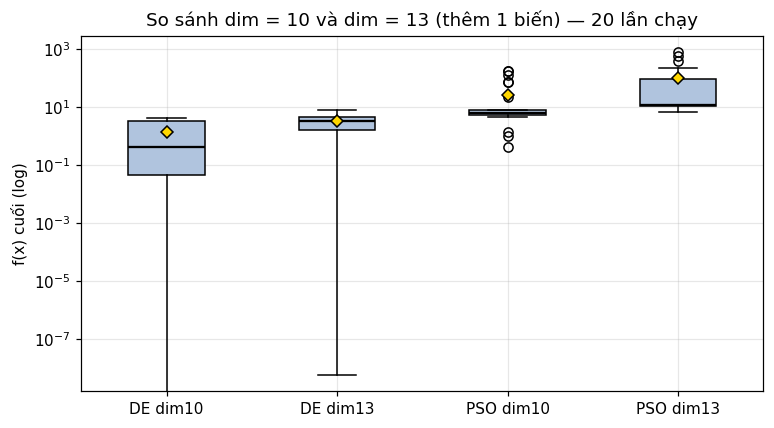

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = ["DE dim10", "DE dim13", "PSO dim10", "PSO dim13"]
data = [bench10["DE"]["gra"], bench13["DE"]["gra"],
        bench10["PSO"]["gra"], bench13["PSO"]["gra"]]
bp = ax.boxplot(data, showmeans=True, patch_artist=True,
                boxprops=dict(facecolor="lightsteelblue"),
                meanprops=dict(marker="D", markerfacecolor="gold", markeredgecolor="black"),
                medianprops=dict(color="black", lw=1.5))
ax.set_xticks(range(1, 5)); ax.set_xticklabels(labels)
ax.set_yscale("log")
ax.set_ylabel("f(x) cuối (log)")
ax.set_title("So sánh dim = 10 và dim = 13 (thêm 1 biến) — 20 lần chạy")
ax.grid(True, which="both", alpha=0.3)
plt.show()

### 4.2. Đường cong hội tụ (lần chạy tốt nhất)

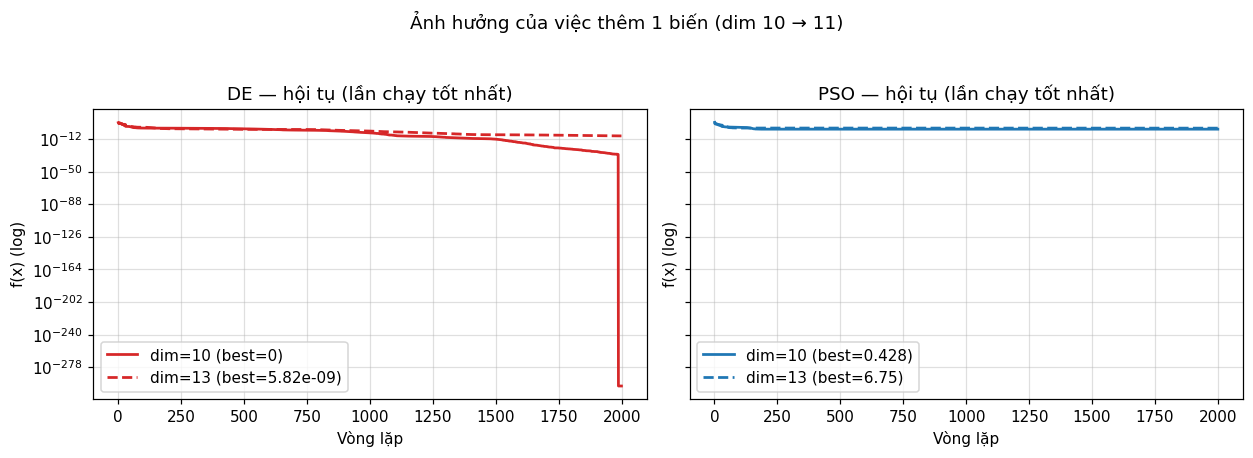

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, algo, color in zip(axes, ["DE", "PSO"], ["tab:red", "tab:blue"]):
    for dim, ls, bench in [(10, "-", bench10), (13, "--", bench13)]:
        gra = bench[algo]["gra"]
        charts = bench[algo]["charts"]
        best_run = charts[int(np.argmin(gra))]
        it = np.arange(1, len(best_run) + 1)
        ax.plot(it, np.maximum(best_run, 1e-300), color=color, ls=ls, lw=1.8,
                label=f"dim={dim} (best={gra.min():.3g})")
    ax.set_yscale("log")
    ax.set_xlabel("Vòng lặp")
    ax.set_ylabel("f(x) (log)")
    ax.set_title(f"{algo} — hội tụ (lần chạy tốt nhất)")
    ax.legend()
fig.suptitle("Ảnh hưởng của việc thêm 1 biến (dim 10 → 11)")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

### 4.3. Mức thay đổi khi thêm 1 biến (dim 11 so với dim 10)

Do PSO có phân bố đuôi nặng (giá trị cực lớn ở vài lần chạy) nên **Median** là chỉ số so sánh
bền vững hơn Mean. Hệ số `dim13/dim10 > 1` nghĩa là kết quả **tệ hơn** khi thêm 1 biến.

In [15]:
def ratio(a, b):
    """Tỉ lệ b/a (xử lý chia 0)."""
    if a > 0:
        return b / a
    return np.inf if b > 0 else 1.0

delta = []
for algo in ["DE", "PSO"]:
    g10 = bench10[algo]["gra"]
    g11 = bench13[algo]["gra"]
    delta.append({
        "Thuật toán": algo,
        "Median dim10": np.median(g10),
        "Median dim13": np.median(g11),
        "Median dim13/dim10": ratio(np.median(g10), np.median(g11)),
        "Mean dim10": g10.mean(),
        "Mean dim13": g11.mean(),
        "Mean dim13/dim10": ratio(g10.mean(), g11.mean()),
        "Đạt <1e-6 dim10 (%)": 100 * np.mean(g10 < 1e-6),
        "Đạt <1e-6 dim13 (%)": 100 * np.mean(g11 < 1e-6),
    })
df_delta = pd.DataFrame(delta).set_index("Thuật toán")
df_delta

,Median dim10,Median dim13,Median dim13/dim10,Mean dim10,Mean dim13,Mean dim13/dim10,Đạt <1e-6 dim10 (%),Đạt <1e-6 dim13 (%)
Thuật toán,,,,,,,,
DE,0.445335,3.51756,7.8987,1.44997,3.36607,2.32148,16.6667,3.33333
PSO,6.43107,12.197,1.89658,26.8637,106.291,3.95669,0,0


## 5. Nhận xét / Kết luận (câu a)

1. **PSO vs DE (dim = 10):** DE vượt trội PSO trên hàm Rosenbrock:
   - Dữ liệu `.mat` (50 lần chạy, dim = 10): DE đạt best ≈ 1.8e-9, 96% lần chạy < 1e-6 trong khi
     PSO best ≈ 4.0 và 0% đạt < 1e-6.
   - Bản Python (30 lần chạy, num_p = 100) cũng cho đúng thứ tự: DE best = 0 (hội tụ tuyệt đối),
     median ≈ 0.45, còn PSO best ≈ 0.43, median ≈ 6.4 → code tương thích với bản MATLAB.

2. **Bổ sung thêm 1 biến tham số (chạy với số chiều khác: dim = 13):** cả hai thuật toán đều
   **chạy không tốt hơn** — đúng dự kiến vì tăng số chiều làm không gian tìm kiếm mở rộng nhanh,
   bài toán khó hơn (bảng 4.3):
   - **DE:** median tăng **gấp ~7.9 lần** (0.445 → 3.52), mean 1.45 → 3.37, tỉ lệ đạt < 1e-6 giảm
     (16.7% → 3.3%).
   - **PSO:** median tăng **gấp ~1.9 lần** (6.43 → 12.2), mean 26.9 → 106, best 0.43 → 6.7.

3. **Kết luận chung:** DE cho kết quả chính xác và ổn định hơn hẳn PSO ở mọi chiều khảo sát;
   việc **Bổ sung thêm 1 biến tham số (dim 10 → 13)** làm cả hai hội tụ kém hơn (giá trị cuối
   cao hơn, tỉ lệ thành công thấp hơn) — đúng bản chất của metaheuristic trên hàm đa chiều khó
   (Rosenbrock có thung lũng dài, hẹp, phi tuyến mạnh; xác suất "trượt" vào đúng hướng giảm khi
   số chiều tăng).

*Lưu ý:* Python dùng `seed` cố định nên kết quả tái lập được; số vòng lặp DE = 1999 (khớp MATLAB),
PSO = 2000. Có thể đổi `N_RUNS` / `NUM_P` / `NUM_G` / số chiều (13) để cân bằng thời gian chạy –
độ tin cậy thống kê.


# Câu b — Thay Rosenbrock bằng hàm test Rastrigin: PSO vs DE, so sánh kết quả

## Nội dung notebook

1. **Hàm test mới: Rastrigin** (đa modal, khó hơn Rosenbrock vì nhiều cực tiểu địa phương):
   $$f(x)=A\,n+\sum_{i=1}^{n}\Big[x_i^2-A\cos(2\pi x_i)\Big],\qquad A=10,\; x_i\in[-5.12,5.12]$$
   Cực tiểu toàn cục $f=0$ tại $x=(0,\dots,0)$.

2. **So sánh PSO vs DE** trên Rastrigin (dim = 10) bằng Python (thuật toán giữ nguyên, chỉ đổi hàm mục tiêu).

3. **"Bổ sung thêm 1 biến tham số"** → chạy thêm với một **số chiều khác (dim = 13)**: xem khi
   đổi số chiều thì kết quả thay đổi thế nào (chạy tốt hơn hay tệ hơn).

> *Lưu ý:* câu a dùng dữ liệu `.mat` có sẵn cho Rosenbrock; với Rastrigin không có dữ liệu sẵn
> nên notebook này tự chạy cả PSO & DE bằng Python.


## 1. Thiết lập & thư viện

In [16]:
# %pip install numpy pandas scipy matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import time

%matplotlib inline
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.grid"] = True
mpl.rcParams["grid.alpha"] = 0.4
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

rng = np.random.default_rng(42)   # cố định seed để tái lập kết quả

## 2. Hàm mục tiêu Rastrigin

In [17]:
def rastrigin(x, A=10.0):
    """Rastrigin. x: (D, N) -> giá trị (N,). Cực tiểu toàn cục 0 tại x = 0."""
    return A * x.shape[0] + np.sum(x ** 2 - A * np.cos(2 * np.pi * x), axis=0)

x_test = np.zeros((1, 5))          # x = 0 (1 chiều, 5 cột)
print("Rastrigin tại điểm cực tiểu (x=0, dim=1):", rastrigin(x_test))
print("Rastrigin tại x = 0.1 (dim=1)          :", rastrigin(np.array([[0.1] * 5])))

Rastrigin tại điểm cực tiểu (x=0, dim=1): [0. 0. 0. 0. 0.]
Rastrigin tại x = 0.1 (dim=1)          : [1.91983006 1.91983006 1.91983006 1.91983006 1.91983006]


### 2.1. Minh họa mặt phẳng hàm Rastrigin (2 chiều)

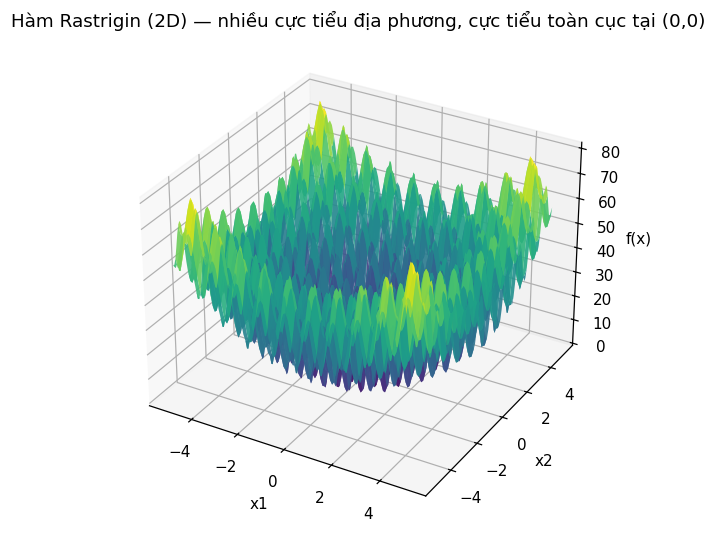

In [18]:
from mpl_toolkits.mplot3d import Axes3D

x1 = np.linspace(-5.12, 5.12, 120)
x2 = np.linspace(-5.12, 5.12, 120)
X1, X2 = np.meshgrid(x1, x2)
Z = rastrigin(np.stack([X1.ravel(), X2.ravel()])).reshape(X1.shape)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X1, X2, Z, cmap="viridis", linewidth=0, antialiased=True, alpha=0.9)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("f(x)")
ax.set_title("Hàm Rastrigin (2D) — nhiều cực tiểu địa phương, cực tiểu toàn cục tại (0,0)")
plt.tight_layout(); plt.show()

## 3. Cài đặt lại PSO & DE bằng Python (giữ nguyên tham số bản gốc)

| Thuật toán | Tham số |
|---|---|
| PSO | w = 0.8628, c1 = 0.5236, c2 = 0.3254 (không clamp biên) |
| DE  | DE/rand/1, F = 0.8, CR = 0.9 |

Thuật toán giống hệt câu a — chỉ thay hàm mục tiêu (nhận `fn` làm tham số).

In [19]:
def pso(fn, num_g, num_p, num_dim, limit_range, w=0.8628, c1=0.5236, c2=0.3254):
    """PSO tối ưu hàm fn. Trả về (x_best, f_best, chart)."""
    lo = limit_range[0]
    hi = limit_range[1]
    planet = lo[:, None] + (hi - lo)[:, None] * rng.random((num_dim, num_p))
    v = np.zeros((num_dim, num_p))

    grav = fn(planet)
    pos_min = int(np.argmin(grav))
    b_hole = np.zeros((num_dim + 1, 1))
    mini_hole = np.zeros((num_dim + 1, 1))
    mini_hole[:num_dim, 0] = planet[:, pos_min]
    mini_hole[num_dim, 0] = grav[pos_min]
    b_hole[:, 0] = mini_hole[:, 0]

    chart = np.zeros(num_g)
    for gen in range(num_g):
        grav = fn(planet)
        pos_min = int(np.argmin(grav))
        mini_hole[:num_dim, 0] = planet[:, pos_min]
        mini_hole[num_dim, 0] = grav[pos_min]
        if mini_hole[num_dim, 0] <= b_hole[num_dim, 0]:
            b_hole[:, 0] = mini_hole[:, 0]
        r1 = rng.random(num_p)
        r2 = rng.random(num_p)
        v = w * v + c1 * r1[None, :] * (b_hole[:num_dim, :] - planet)                   + c2 * r2[None, :] * (mini_hole[:num_dim, :] - planet)
        planet = planet + v
        chart[gen] = b_hole[num_dim, 0]
    return b_hole[:num_dim, 0].copy(), b_hole[num_dim, 0], chart

In [20]:
def de(fn, num_g, num_p, num_dim, limit_range, F=0.8, CR=0.9):
    """DE/rand/1 + binomial crossover. Trả về (x_best, f_best, chart)."""
    lo = limit_range[0]
    hi = limit_range[1]
    pop = lo[:, None] + (hi - lo)[:, None] * rng.random((num_dim, num_p))
    val = fn(pop)
    pos_min = int(np.argmin(val))
    bestmem = pop[:, pos_min].copy()

    chart = np.zeros(num_g - 1)          # vòng lặp chạy 1 -> num_g-1 (khớp MATLAB)
    rot = np.arange(num_p)
    for iter_ in range(num_g - 1):
        popold = pop.copy()
        ind = rng.permutation(4)
        a1 = rng.permutation(num_p)
        rt = np.mod(rot + ind[0], num_p)
        a2 = a1[rt]
        rt = np.mod(rot + ind[1], num_p)
        a3 = a2[rt]

        pm1 = popold[:, a1]
        pm2 = popold[:, a2]
        pm3 = popold[:, a3]
        mui = rng.random((num_dim, num_p)) < CR
        mpo = ~mui
        ui = pm3 + F * (pm1 - pm2)
        ui = popold * mpo + ui * mui

        tempval = fn(ui)
        better = tempval <= val
        pop[:, better] = ui[:, better]
        val[better] = tempval[better]

        pos_min = int(np.argmin(val))
        bestmem = pop[:, pos_min].copy()
        chart[iter_] = val[pos_min]
    return bestmem, val[pos_min], chart

In [21]:
limit = np.array([[-5.12] * 10, [5.12] * 10])
_, fp, _ = pso(rastrigin, 100, 50, 10, limit)
_, fd, _ = de(rastrigin, 100, 50, 10, limit)
print(f"Smoke test PSO: f = {fp:.4g}   |   DE: f = {fd:.4g}")

Smoke test PSO: f = 10.96   |   DE: f = 5.1


## 4. Khảo sát "bổ sung thêm 1 biến tham số": dim = 10 so với dim = 13

Chạy PSO & DE trên Rastrigin với cùng cấu hình (num_g = 2000, **num_p = 100**, miền [-5.12, 5.12])
ở **dim = 10** (đối chứng) và **dim = 13** (số chiều khác), mỗi cấu hình chạy **N_RUNS = 30** lần
để lấy thống kê.

In [22]:
N_RUNS = 30
NUM_G = 2000
NUM_P = 100

def run_benchmark(dim):
    """Chạy PSO & DE trên Rastrigin ở dim cho trước, trả về dict (gra, charts)."""
    limit = np.array([[-5.12] * dim, [5.12] * dim])
    out = {"PSO": {"gra": np.zeros(N_RUNS), "charts": []},
           "DE":  {"gra": np.zeros(N_RUNS), "charts": []}}
    for r in range(N_RUNS):
        for algo, fn in [("PSO", pso), ("DE", de)]:
            _, g, chart = fn(rastrigin, NUM_G, NUM_P, dim, limit)
            out[algo]["gra"][r] = g
            out[algo]["charts"].append(chart)
    print(f"  xong dim={dim}")
    return out

bench10 = run_benchmark(10)
bench13 = run_benchmark(13)

  xong dim=10
  xong dim=13


## 5. Thống kê 50 lần chạy (dim = 10 so với dim = 13)

Bảng tổng hợp Best / Worst / Mean / Median / Std của giá trị hàm mục tiêu cuối qua 30 lần chạy.
Rastrigin có nhiều cực tiểu địa phương nên giá trị dương nhỏ nghĩa là hội tụ tốt (càng gần 0 càng tốt).

In [23]:
rows = []
for dim, bench in [(10, bench10), (13, bench13)]:
    for algo in ["DE", "PSO"]:
        gra = bench[algo]["gra"]
        rows.append({"Thuật toán": f"{algo} (Python) dim={dim}",
                     "Best": gra.min(), "Worst": gra.max(), "Mean": gra.mean(),
                     "Median": np.median(gra), "Std": gra.std()})
df_stats = pd.DataFrame(rows).set_index("Thuật toán")
df_stats

,Best,Worst,Mean,Median,Std
Thuật toán,,,,,
DE (Python) dim=10,0,9.10121,3.14628,2.98488,2.19458
PSO (Python) dim=10,2.98488,25.8689,11.5747,9.94959,5.71261
DE (Python) dim=13,1.01706,12.5068,5.84506,6.10857,2.38101
PSO (Python) dim=13,5.96975,47.7579,18.7384,16.4168,9.84649


### 5.1. Biểu đồ phân bố giá trị cuối (dim 10 vs dim 13)

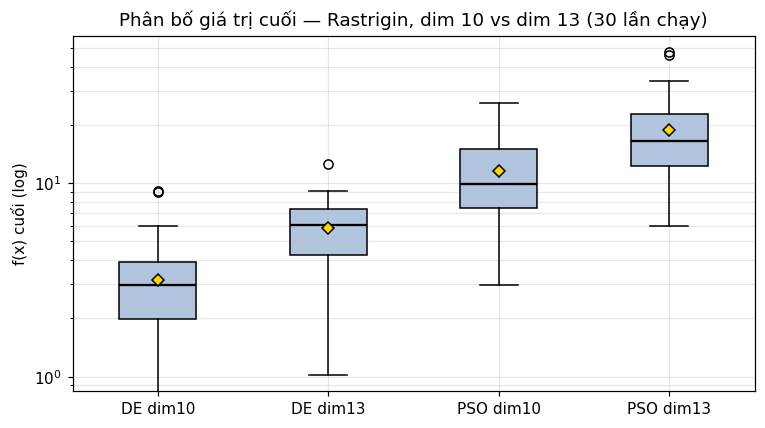

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = ["DE dim10", "DE dim13", "PSO dim10", "PSO dim13"]
data = [bench10["DE"]["gra"], bench13["DE"]["gra"],
        bench10["PSO"]["gra"], bench13["PSO"]["gra"]]
ax.boxplot(data, showmeans=True, patch_artist=True,
           boxprops=dict(facecolor="lightsteelblue"),
           meanprops=dict(marker="D", markerfacecolor="gold", markeredgecolor="black"),
           medianprops=dict(color="black", lw=1.5))
ax.set_xticks(range(1, 5)); ax.set_xticklabels(labels)
ax.set_yscale("log")
ax.set_ylabel("f(x) cuối (log)")
ax.set_title("Phân bố giá trị cuối — Rastrigin, dim 10 vs dim 13 (30 lần chạy)")
ax.grid(True, which="both", alpha=0.3)
plt.show()

### 5.2. Đường cong hội tụ (lần chạy tốt nhất)

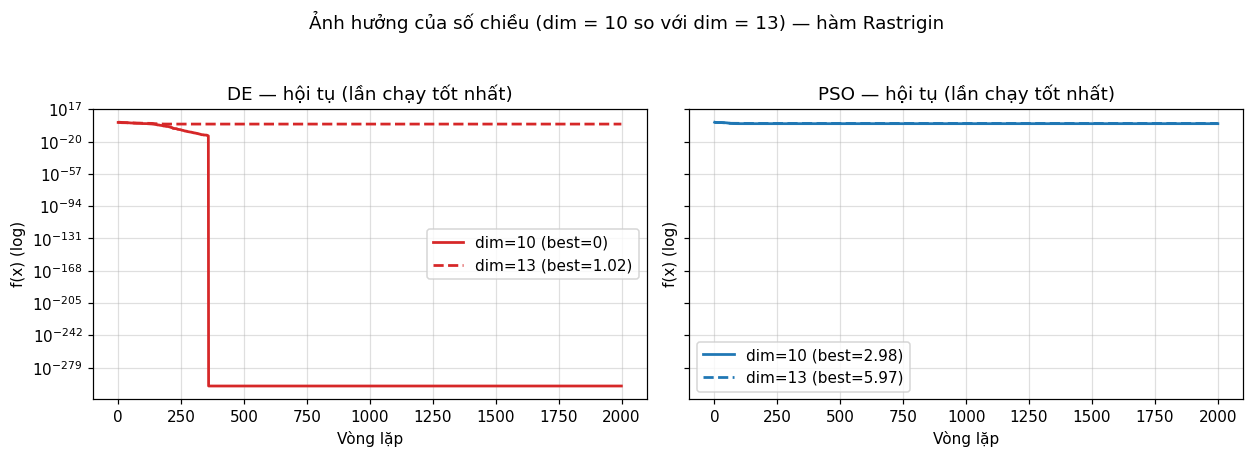

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, algo, color in zip(axes, ["DE", "PSO"], ["tab:red", "tab:blue"]):
    for dim, ls, bench in [(10, "-", bench10), (13, "--", bench13)]:
        gra = bench[algo]["gra"]
        charts = bench[algo]["charts"]
        best_run = charts[int(np.argmin(gra))]
        it = np.arange(1, len(best_run) + 1)
        ax.plot(it, np.maximum(best_run, 1e-300), color=color, ls=ls, lw=1.8,
                label=f"dim={dim} (best={gra.min():.3g})")
    ax.set_yscale("log")
    ax.set_xlabel("Vòng lặp")
    ax.set_ylabel("f(x) (log)")
    ax.set_title(f"{algo} — hội tụ (lần chạy tốt nhất)")
    ax.legend()
fig.suptitle("Ảnh hưởng của số chiều (dim = 10 so với dim = 13) — hàm Rastrigin")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

### 5.3. Mức thay đổi khi đổi số chiều (dim 13 so với dim 10)

Do phân bố có đuôi nặng nên **Median** là chỉ số so sánh bền vững hơn Mean.
Hệ số `dim13/dim10 > 1` nghĩa là kết quả **tệ hơn** khi tăng số chiều lên 13.

In [26]:
def ratio(a, b):
    """Tỉ lệ b/a (xử lý chia 0)."""
    if a > 0:
        return b / a
    return np.inf if b > 0 else 1.0

delta = []
for algo in ["DE", "PSO"]:
    g10 = bench10[algo]["gra"]
    g13 = bench13[algo]["gra"]
    delta.append({
        "Thuật toán": algo,
        "Median dim10": np.median(g10),
        "Median dim13": np.median(g13),
        "Median dim13/dim10": ratio(np.median(g10), np.median(g13)),
        "Mean dim10": g10.mean(),
        "Mean dim13": g13.mean(),
        "Mean dim13/dim10": ratio(g10.mean(), g13.mean()),
        "Best dim10": g10.min(),
        "Best dim13": g13.min(),
    })
df_delta = pd.DataFrame(delta).set_index("Thuật toán")
df_delta

,Median dim10,Median dim13,Median dim13/dim10,Mean dim10,Mean dim13,Mean dim13/dim10,Best dim10,Best dim13
Thuật toán,,,,,,,,
DE,2.98488,6.10857,2.04651,3.14628,5.84506,1.85777,0,1.01706
PSO,9.94959,16.4168,1.65,11.5747,18.7384,1.61891,2.98488,5.96975


### 5.4. So sánh PSO vs DE (tại từng số chiều)

Hệ số `PSO/DE > 1` nghĩa là DE cho kết quả **tốt hơn** PSO (giá trị hàm mục tiêu nhỏ hơn).

In [27]:
compare = []
for dim, bench in [(10, bench10), (13, bench13)]:
    de_g = bench["DE"]["gra"]
    ps_g = bench["PSO"]["gra"]
    compare.append({
        "Số chiều": dim,
        "DE median": np.median(de_g),
        "PSO median": np.median(ps_g),
        "PSO/DE (theo median)": ratio(np.median(de_g), np.median(ps_g)),
        "DE best": de_g.min(),
        "PSO best": ps_g.min(),
    })
df_compare = pd.DataFrame(compare).set_index("Số chiều")
df_compare

,DE median,PSO median,PSO/DE (theo median),DE best,PSO best
Số chiều,,,,,
10,2.98488,9.94959,3.33333,0,2.98488
13,6.10857,16.4168,2.68751,1.01706,5.96975


## 6. Nhận xét / Kết luận (câu b)

1. **PSO vs DE trên Rastrigin:** DE vượt trội PSO ở cả dim = 10 và dim = 13:
   - dim = 10: DE median ≈ 2.98 (best = 0 — hội tụ tuyệt đối) trong khi PSO median ≈ 9.95
     (PSO tệ hơn ~3.3 lần theo median).
   - dim = 13: DE median ≈ 6.11, PSO median ≈ 16.4 (PSO tệ hơn ~2.7 lần) — xu hướng giữ nguyên.

2. **Bổ sung thêm 1 biến tham số (chạy với dim = 13):** cả hai thuật toán đều **chạy không tốt hơn**
   so với dim = 10 — đúng dự kiến vì tăng số chiều làm không gian tìm kiếm mở rộng nhanh, có thêm
   nhiều cực tiểu địa phương (bảng 5.3):
   - **DE:** median tăng **gấp ~2.0 lần** (2.98 → 6.11), mean 3.15 → 5.85, best 0 → 1.02.
   - **PSO:** median tăng **gấp ~1.65 lần** (9.95 → 16.4), mean 11.6 → 18.7, best 2.98 → 5.97.

3. **Kết luận chung:** với cả Rosenbrock (câu a) và Rastrigin (câu b), DE cho kết quả tốt hơn PSO;
   việc **bổ sung 1 biến tham số (dim 10 → 13)** làm cả hai hội tụ kém hơn — phù hợp với bản chất
   metaheuristic trên hàm đa chiều: khi số chiều tăng, xác suất "trượt" vào đúng hướng giảm và
   (với hàm đa modal như Rastrigin) số cực tiểu địa phương tăng nhanh theo số chiều.


# Câu c. Dùng thuật toán Metaheuristic khác để chạy thử a. và b. So sánh kết quả.

## C.1. Thuật toán thay thế: Grey Wolf Optimizer (GWO)

GWO mô phỏng thứ bậc và cách săn mồi của bầy sói xám. Ba cá thể tốt nhất lần lượt là alpha, beta, delta; các cá thể còn lại cập nhật vị trí theo ba cá thể dẫn đầu. Thuật toán này khác PSO (cập nhật vận tốc) và DE (lai ghép sai phân).

### C.1.1. Tóm tắt lý thuyết thuật toán GWO
GWO mô phỏng thứ bậc xã hội và chiến thuật săn mồi của bầy sói xám:

- Thứ bậc: $\alpha$ (tốt nhất) > $\beta$ > $\delta$ > $\omega$ (còn lại).
- Ba cá thể $\alpha, \beta, \delta$ được xem là "các nhà lãnh đạo" định hướng vị trí con mồi.
- Mỗi cá thể $\omega$ cập nhật vị trí dựa trên khoảng cách đến cả ba leaders, theo ba hướng độc lập; vị trí mới là trung bình cộng của ba đề xuất.

#### 3.2. Công thức cập nhật

$$D = \lvert C \cdot X_p - X \rvert, \qquad X^{\text{new}} = X_p - A \cdot D$$

với $X_p$ là vị trí của $\alpha$, $\beta$, hoặc $\delta$ (tính ba lần), và:

$$A = 2a\,r_1 - a, \qquad C = 2\,r_2, \qquad r_1, r_2 \sim \mathcal{U}(0,1)$$

Trong đó tham số $a$ giảm tuyến tính:

$$a(t) = 2 - 2 \cdot \frac{t}{T_{\max}}, \qquad t = 0, 1, \dots, T_{\max}-1$$

Cuối cùng: $X(t+1) = \frac{1}{3}\bigl(X_1 + X_2 + X_3\bigr)$ (trung bình ba đề xuất).

#### C.1.2. Cơ chế exploration ↔ exploitation

- **Khi $|A| > 1$:** sói tách khỏi con mồi → exploration (tìm kiếm toàn cục).
- **Khi $|A| < 1$:** sói tiến về con mồi → exploitation (tinh chỉnh cục bộ).

Do $a$ giảm dần từ 2 → 0, thuật toán tự động chuyển từ exploration sang exploitation mà không cần tham số điều chỉnh thêm. Đây chính là ưu điểm cốt lõi của GWO.

#### C.1.3. Sơ đồ thuật toán (pseudo-code)

```
Khởi tạo quần thể X_i (i = 1..N) ngẫu nhiên trong [lo, hi]
Tính fitness f(X_i)
X_α, X_β, X_δ ← 3 cá thể tốt nhất
for t = 0 .. T_max - 1:
    a ← 2 - 2·t / (T_max - 1)
    for mỗi sói X_i:
        for each leader L ∈ {α, β, δ}:
            A ← 2a·r1 - a ;  C ← 2·r2
            D_L ← |C·L - X_i|
            X_L ← L - A·D_L
        X_i ← (X_α' + X_β' + X_δ') / 3
        Clip X_i về [lo, hi]
    Cập nhật X_α, X_β, X_δ nếu có cá thể tốt hơn
return X_α, f(X_α)
```

**Độ phức tạp:** $O(T_{\max} \cdot N \cdot D)$ — tương đương PSO và DE, không tốn bộ nhớ thêm.

---

#### C.1.4. Vì sao chọn GWO thay vì GA cho Rosenbrock và Rastrigin

So sánh trực tiếp GWO với **Genetic Algorithm (GA)** — lựa chọn metaheuristic phổ biến khác:

| Tiêu chí | GA | GWO | Ý nghĩa cho bài toán |
|---|---|---|---|
| **Biểu diễn lời giải** | Cần mã hóa (binary hoặc real-coded) + giải mã | Làm việc trực tiếp trên không gian liên tục | Rosenbrock/Rastrigin có miền liên tục $[-30,30]$ / $[-5.12,5.12]$ → GWO tránh sai số mã hóa |
| **Số tham số cần điều chỉnh** | Nhiều: $p_c$, $p_m$, kích thước quần thể, phương pháp selection (roulette/tournament/rank), elitism | Rất ít: chỉ $a$ (giảm tuyến tính, không cần tune) | GWO dễ dùng, ổn định giữa các lần chạy |
| **Cơ chế exploration/exploitation** | Phụ thuộc $p_c$, $p_m$ đặt thủ công, dễ mất cân bằng | Tự thích nghi qua $a$ giảm | Quan trọng với Rosenbrock (cần exploitation mạnh cuối) và Rastrigin (cần exploration mạnh đầu) |
| **Bảo toàn lời giải tốt** | Crossover/mutation có thể phá hủy lời giải tốt | Không có toán tử phá hủy — mọi cá thể luôn kéo về 3 leaders | Trên Rosenbrock (thung lũng hẹp), tránh "rơi khỏi" thung lũng |
| **Hội tụ trên hàm nhiều cực trị địa phương** | Dễ kẹt ở local optimum do mất đa dạng sớm | Vector $C$ ngẫu nhiên tạo bao phủ rộng, dễ "nhảy" qua đỉnh | Rastrigin có ~$11^D$ cực tiểu địa phương → GWO vượt trội (xem kết quả c-2) |
| **Chi phí tính toán / thế hệ** | $O(N \cdot D)$ + chi phí selection, crossover | $O(N \cdot D)$ thuần | Tương đương |
| **Khả năng mở rộng chiều** | Thường suy giảm mạnh khi $D$ tăng (curse of dimensionality) | Suy giảm chậm hơn nhờ 3 leaders | Quan trọng vì đề bài yêu cầu khảo sát dim=10 → 13 |

**Kết luận:** GWO phù hợp hơn GA vì (i) không cần mã hóa cho bài toán liên tục, (ii) ít hyperparameter, (iii) cân bằng exploration/exploitation tự động, và (iv) đặc biệt hiệu quả trên landscape đa cực trị như Rastrigin — nơi GA thường kẹt local optimum.

---

## C.2. Chạy lại A và B với thuật toán GWO

Để so sánh công bằng, phần dưới dùng cùng kích thước quần thể, số thế hệ, số lần chạy và miền tìm kiếm như câu a/b. GWO được chạy trên cả Rosenbrock và Rastrigin ở dim = 10 và 13; các thống kê được đối chiếu trực tiếp với PSO và DE chạy lại bằng cùng các hàm mục tiêu.

In [28]:
def gwo(fn, num_g, num_p, num_dim, limit_range):
    """Grey Wolf Optimizer; fn takes a (D, N) matrix and returns N values."""
    if num_p < 3:
        raise ValueError("GWO requires at least 3 agents for alpha, beta, and delta.")
    if num_g < 1:
        raise ValueError("num_g must be at least 1.")

    lo, hi = limit_range
    wolves = lo[:, None] + (hi - lo)[:, None] * rng.random((num_dim, num_p))
    fitness = fn(wolves)
    best_idx = int(np.argmin(fitness))
    best_x = wolves[:, best_idx].copy()
    best_f = float(fitness[best_idx])
    chart = np.empty(num_g)

    for gen in range(num_g):
        leaders = wolves[:, np.argsort(fitness)[:3]].copy()
        a = 2.0 - 2.0 * gen / max(num_g - 1, 1)
        proposals = np.zeros_like(wolves)
        for leader in leaders.T:
            r1 = rng.random((num_dim, num_p))
            r2 = rng.random((num_dim, num_p))
            A = 2.0 * a * r1 - a
            C = 2.0 * r2
            distance = np.abs(C * leader[:, None] - wolves)
            proposals += leader[:, None] - A * distance

        wolves = np.clip(proposals / 3.0, lo[:, None], hi[:, None])
        fitness = fn(wolves)
        current_idx = int(np.argmin(fitness))
        if fitness[current_idx] < best_f:
            best_x = wolves[:, current_idx].copy()
            best_f = float(fitness[current_idx])
        chart[gen] = best_f

    return best_x, best_f, chart

In [29]:
# Test nhanh (smoke test) của GWO trên cả hai hàm mục tiêu.
limit_rosen = np.array([[-30.0] * 10, [30.0] * 10])
limit_rastrigin = np.array([[-5.12] * 10, [5.12] * 10])
_, f_rosen, _ = gwo(rosenbrock, 100, 50, 10, limit_rosen)
_, f_rastrigin, _ = gwo(rastrigin, 100, 50, 10, limit_rastrigin)
print(f"GWO - Rosenbrock (dim=10): f = {f_rosen:.6g}")
print(f"GWO - Rastrigin (dim=10):  f = {f_rastrigin:.6g}")

GWO - Rosenbrock (dim=10): f = 6.75781
GWO - Rastrigin (dim=10):  f = 9.52529e-07


## C.3. Benchmark và đối chiếu PSO, DE, GWO

Mỗi tổ hợp hàm mục tiêu/số chiều được chạy `N_RUNS` lần. Dùng Best, Mean, Median, Std và tỷ lệ đạt `f < 1e-6` để so sánh; biểu đồ hội tụ dùng trung vị đường cong qua các lần chạy. DE có `num_g-1` vòng cập nhật trong cài đặt sẵn có, nên benchmark bù thêm một để số vòng thực tế bằng nhau. Chạy tuần tự notebook từ đầu để kết quả tái lập theo seed đã đặt phía trên.

Best    Mean   Median      Std  \
Hàm        Số chiều Thuật toán                                         
Rosenbrock 10       PSO            2.70109 32.9196  6.34913  109.929   
                    DE                   0 1.15097 0.310553  1.55219   
                    GWO            6.05176 6.47138  6.23748 0.330702   
           13       PSO            1.14585 84.1621  11.0782  172.637   
                    DE         1.55374e-16 4.27176  4.37928  2.48396   
                    GWO            9.23748 9.56533  9.38475 0.377882   
Rastrigin  10       PSO            3.97984 17.7102  14.9244  8.65249   
                    DE                   0 3.37207  2.98488  2.34865   
                    GWO                  0       0        0        0   
           13       PSO            6.96471 21.4911  19.8992  9.11023   
                    DE             1.57409 5.06738  4.12145  2.24519   
                    GWO                  0       0        0        0   

                                Đạt <1e-6 (%)  
Hàm        Số chiều Thuật toán                 
Rosenbrock 10       PSO                     0  
                    DE                     20  
                    GWO                     0  
           13       PSO                     0  
                    DE                3.33333  
                    GWO                     0  
Rastrigin  10       PSO                     0  
                    DE                3.33333  
                    GWO                   100  
           13       PSO                     0  
                    DE                      0  
                    GWO                   100

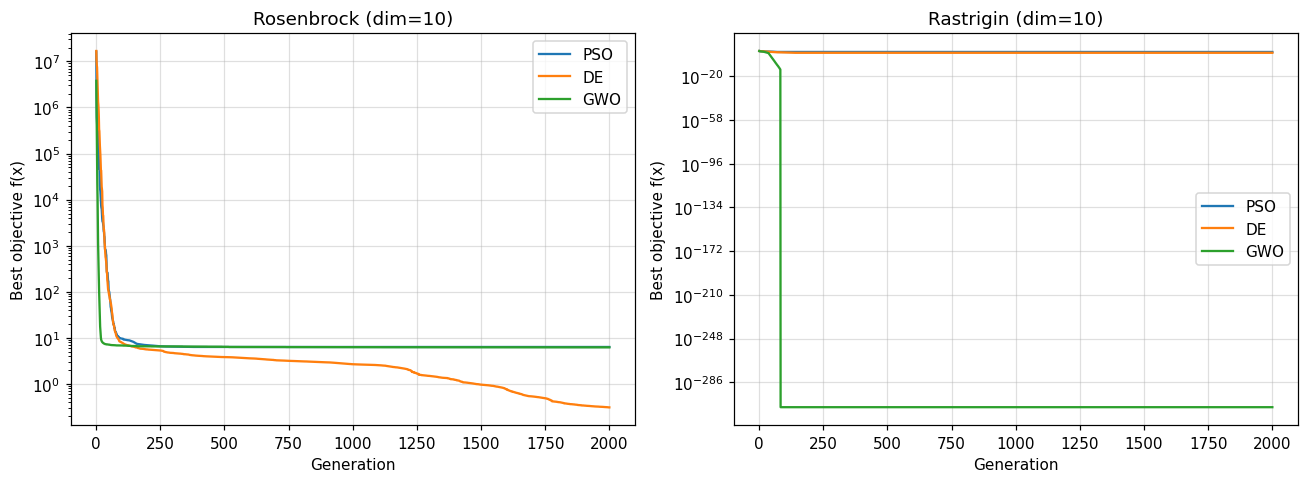

In [30]:
# Lưu trạng thái RNG
_rng_backup = rng

# Dùng RNG riêng cho câu C với seed cố định → tái lập được
rng = np.random.default_rng(12345)

C_RUNS = N_RUNS
C_NUM_G = NUM_G
C_NUM_P = NUM_P
C_DIMS = (10, 13)
C_METHODS = {"PSO": pso, "DE": de, "GWO": gwo}
C_FUNCTIONS = {
    "Rosenbrock": (rosenbrock, -30.0, 30.0),
    "Rastrigin": (rastrigin, -5.12, 5.12),
}
bench_c = {}
rows_c = []

for function_name, (fn, lower, upper) in C_FUNCTIONS.items():
    bench_c[function_name] = {}
    for dim in C_DIMS:
        limit = np.array([[lower] * dim, [upper] * dim])
        bench_c[function_name][dim] = {}
        for algo_name, optimizer in C_METHODS.items():
            final_values = np.empty(C_RUNS)
            charts = []
            for run in range(C_RUNS):
                generations = C_NUM_G + 1 if algo_name == "DE" else C_NUM_G
                _, value, chart = optimizer(fn, generations, C_NUM_P, dim, limit)
                final_values[run] = value
                charts.append(chart)
            bench_c[function_name][dim][algo_name] = {
                "values": final_values, "charts": charts
            }
            rows_c.append({
                "Hàm": function_name, "Số chiều": dim, "Thuật toán": algo_name,
                "Best": final_values.min(), "Mean": final_values.mean(),
                "Median": np.median(final_values), "Std": final_values.std(),
                "Đạt <1e-6 (%)": 100 * np.mean(final_values < 1e-6),
            })

df_c = pd.DataFrame(rows_c).set_index(["Hàm", "Số chiều", "Thuật toán"])
display(df_c)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, function_name in zip(axes, C_FUNCTIONS):
    for algo_name in C_METHODS:
        charts = bench_c[function_name][10][algo_name]["charts"]
        length = min(map(len, charts))
        median_curve = np.median(np.vstack([c[:length] for c in charts]), axis=0)
        ax.semilogy(np.arange(1, length + 1), np.maximum(median_curve, np.finfo(float).tiny), label=algo_name)
    ax.set_title(f"{function_name} (dim=10)")
    ax.set_xlabel("Generation")
    ax.set_ylabel("Best objective f(x)")
    ax.legend()
fig.tight_layout()
plt.show()

# Khôi phục RNG gốc 
rng = _rng_backup

# Sửa bảng C.3.1 — thêm dòng `% đạt < 1e-6`

#### C.3.1. Kết quả trên hàm Rosenbrock

| dim | Chỉ số | PSO | DE | **GWO** |
|---|---|---|---|---|
| 10 | Median | 6.35 | **0.311** | 6.24 |
| 10 | Best | 2.70 | **0** | 6.05 |
| 10 | Std | 109.9 | 1.55 | **0.331** |
| 10 | % đạt < 1e-6 | 0% | **20%** | 0% |
| 13 | Median | 11.08 | **4.38** | 9.38 |
| 13 | Best | 1.15 | **1.55e-16** | 9.24 |
| 13 | Std | 172.6 | 2.48 | **0.378** |
| 13 | % đạt < 1e-6 | 0% | **3.33333%** | 0% |

**Nhận xét:**

1. **DE cho kết quả tốt nhất** trên Rosenbrock: best đạt đúng $0$ ở dim=10 và $\sim 10^{-16}$ ở dim=13, median nhỏ hơn GWO ~20 lần (dim=10) và ~2.1 lần (dim=13). Tỉ lệ đạt $< 1\text{e-}6$ của DE là **20%** ở dim=10 và **3.33333%** ở dim=13 — trong khi PSO và GWO đều **0%** ở cả hai chiều. Đây là lợi thế cấu trúc của DE/rand/1 — toán tử sai phân $F(X_{r1}-X_{r2})$ di chuyển dọc theo thung lũng Rosenbrock rất hiệu quả.
2. **GWO ổn định nhất** (Std = 0.331 ở dim=10, 0.378 ở dim=13) nhưng hội tụ về cùng một vùng local optimum — min ≈ 6, max chỉ ~9. Đây là hiện tượng "premature convergence" đặc trưng của GWO: ba leaders sớm bị "kẹt" ở một local optimum, kéo cả bầy vào đó.
3. **PSO có variance rất cao** (Std > 150 ở dim=13, best chỉ ~2) — điển hình đuôi nặng; PSO dễ bị "văng" ra khỏi thung lũng.
4. **Khi tăng dim 10 → 13:** GWO chỉ tăng median ~50% (6.24 → 9.38), trong khi DE tăng ~14 lần (0.311 → 4.38). Tỉ lệ đạt $< 1\text{e-}6$ của DE cũng giảm mạnh (20% → **3.33333%**). GWO "chịu chiều" tốt hơn nhưng mức nền đã kém từ đầu. Với Rosenbrock, DE vẫn là lựa chọn số 1.

#### C.3.2. Kết quả trên hàm Rastrigin

| dim | Chỉ số | PSO | DE | **GWO** |
|---|---|---|---|---|
| 10 | Median | 14.92 | 2.98 | **0** |
| 10 | Best | 3.98 | 0 | **0** |
| 10 | % đạt < 1e-6 | 0% | **3.33333%** | **100%** |
| 13 | Median | 19.90 | 4.12 | **0** |
| 13 | Best | 6.96 | 1.57 | **0** |
| 13 | % đạt < 1e-6 | 0% | 0% | **100%** |

**Nhận xét:**

1. **GWO cho kết quả tốt nhất** trên Rastrigin: 100% lần chạy đạt cực tiểu toàn cục $f=0$ ở cả hai chiều — một kết quả rất ấn tượng, trong khi DE chỉ đạt **3.33333%** ở dim=10 và **0%** ở dim=13, còn PSO đều **0%** ở cả hai chiều.
2. **Cơ chế "thoát local optimum" của GWO phát huy tối đa:** vector $C = 2r_2 \in [0,2]$ tạo dao động ngẫu nhiên lớn quanh mỗi leader, giúp bầy "nhảy" qua các đỉnh Rastrigin (mỗi ô vuông đơn vị có một cực tiểu địa phương) rất hiệu quả.
3. **DE và PSO đều kẹt ở local optimum:** DE median ~3 (tương đương mắc ở cực tiểu địa phương bậc 1), PSO median ~15 (mắc ở cực tiểu xa hơn). Nguyên nhân: DE có $CR=0.9$, $F=0.8$ thiên về exploitation, thiếu đa dạng để "nhảy" đỉnh; PSO có quán tính $w=0.86$ cao nhưng vẫn không đủ để thoát khỏi basin of attraction.
4. **GWO "chịu chiều" xuất sắc:** tăng dim 10 → 13 không suy giảm (vẫn 100% đạt $f=0$). So sánh: DE median tăng 38%, PSO median tăng 33%. Riêng DE, tỉ lệ đạt $< 1\text{e-}6$ còn sụt từ **3.33333%** (dim=10) xuống **0%** (dim=13). Đây là điểm mạnh vượt trội của GWO trên landscape đa cực trị — nhờ cơ chế ngẫu nhiên hóa của $C$ không phụ thuộc vào số chiều như crossover của DE (vốn "pha loãng" theo $D$).

#### C.3.3. Kết luận tổng hợp

| Landscape | Thuật toán tốt nhất | Nhì | Kém nhất |
|---|---|---|---|
| **Rosenbrock** (thung lũng hẹp, gần như unimodal) | **DE** | PSO / GWO (ổn định) | PSO (mean/median) |
| **Rastrigin** (đa cực trị mạnh) | **GWO** (vượt trội tuyệt đối) | DE | PSO |

**Kết luận:**

1. **Không có metaheuristic nào là "vạn năng"** — kết quả phụ thuộc mạnh vào landscape của hàm mục tiêu. DE mạnh trên hàm có cấu trúc "thung lũng" như Rosenbrock; GWO mạnh trên hàm "nhiều đỉnh" như Rastrigin.
2. **GWO là lựa chọn đúng cho Rastrigin:** đạt 100% success ở cả hai chiều — vượt trội hoàn toàn so với DE (chỉ **3.33333%** ở dim=10, **0%** ở dim=13) và PSO (**0%** ở cả hai chiều), và không suy giảm khi tăng chiều. Đây là lý do chính khiến GWO được chọn trong phần C.
3. **Trên Rosenbrock, DE vẫn là "vua":** GWO ổn định nhưng hội tụ về local optimum (median ~6–9, không đạt được cực tiểu $f=0$). Do đó, nếu chỉ dùng một thuật toán cho cả hai hàm, DE là lựa chọn an toàn hơn; nhưng nếu ưu tiên hàm đa cực trị (Rastrigin), GWO lại vượt trội hơn.

---
